# Real-Data Analysis Workflow: Landing Page A/B Testing
## Modular Functional Architecture
**Course:** MT3194 — Statistical Inference (IISER Pune)  
**Track:** Dataset Hygiene, Exploratory Analysis & Empirical Inference (Sections 1 & 4)  
**Dataset:** E-Commerce Landing Page A/B Testing Dataset (`ab_data.csv`)  
**Target Storage:** `group_project/data/ab_data.csv`

---

### 🧭 End-to-End Workflow Roadmap
$$\text{Raw Data Ingestion} \longrightarrow \text{Data Hygiene & Cleaning} \longrightarrow \text{Sanity Checks (SRM)} \longrightarrow \text{Statistical Tests (LRT & } Z\text{)} \longrightarrow \text{Confidence Intervals} \longrightarrow \text{Business Verdict}$$

### 🏗️ Architecture Design: Modular Functional Pipeline
In this notebook, the entire real-world statistical inference pipeline is organized into **self-contained phase functions**:
1. `phase_1_data_hygiene(raw_path=None)`: Ingestion, schema audit, routing anomaly removal, duplicate deduplication, and funnels.
2. `phase_2_exploratory_analysis(df_clean)`: Empirical counts, conversion rates, Pearson Sample Ratio Mismatch (SRM) test, and 23-day temporal checks.
3. `phase_3_hypothesis_testing(metrics)`: Two-sample pooled $Z$-test, Likelihood Ratio Test ($G^2$ deviance), and Wilks' theorem Taylor equivalence.
4. `phase_4_confidence_intervals(metrics)`: Wald Normal, Wilson Score (Newcombe), and Profile Likelihood (LRT inversion) 95% confidence intervals.
5. `phase_5_business_synthesis(metrics, test_results, ci_results)`: Statistical vs. practical significance against MDE, ROI evaluation, and executive scorecard.

Each phase preserves all underlying derivations, intermediate calculations, validation checks, and publication-grade visualizations. All phases are executed sequentially at the end of the notebook.

---
## 0. Setup and Environment Configuration
In this section, we import core computational libraries (`numpy`, `pandas`, `scipy.stats`, `scipy.optimize`) and graphics packages (`matplotlib`, `seaborn`). We also configure high-resolution graphics and styling for publication-grade output.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats, optimize
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings

# Suppress minor warnings for clean report generation
warnings.filterwarnings('ignore')

# Set visual aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 13

print(f"NumPy version:   {np.__version__}")
print(f"Pandas version:  {pd.__version__}")
print(f"SciPy version:   {stats.__name__} (scipy ready)")
print("Python runtime environment successfully initialized.")

NumPy version:   2.4.3
Pandas version:  3.0.1
SciPy version:   scipy.stats (scipy ready)
Python runtime environment successfully initialized.


---
## Phase 1: Data Ingestion & Data Hygiene (Section 1)

### Mathematical & Practical Objectives:
1. **Step 1.1: Ingestion & Schema Inspection**
   - Ingest raw dataset `ab_data.csv` ($N_{\text{raw}} \approx 294,478$ rows).
   - Expected columns: `user_id` (Integer), `timestamp` (DateTime), `group` (control/treatment), `landing_page` (old_page/new_page), `converted` (Binary: $0/1$).
   - Check for missing values across all features (ensure exactly 0 nulls).

2. **Step 1.2: Audit the Routing Mismatch Bug**
   - In real-world experimentation platforms, server routing glitches can deliver the wrong page to an assigned cohort:
     - Control users served `new_page`
     - Treatment users served `old_page`
   - **Decision Rule:** Drop all mismatched rows (expected $\approx 3,893$ rows, $\approx 1.32\%$ of data).
   - **Statistical Justification:** We cannot verify whether mismatched users received the intended experimental exposure. Retaining them induces server-side selection bias, violating the assumption of clean experimental randomization (threat to internal validity).

3. **Step 1.3: Audit Duplicate Users**
   - Detect repeat visits by the same `user_id`.
   - **Decision Rule:** Retain only the user's first interaction, dropping subsequent visits.
   - **Statistical Justification:** Bernoulli hypothesis tests and asymptotic likelihood ratio tests strictly require observations to be **independent and identically distributed (i.i.d.)**. Multiple observations from the same user induce intra-subject correlation, which violates sample independence and falsely deflates variance.
   - **Target Clean Benchmark Size:** $N_{\text{clean}} = 290,584$ records saved to `group_project/data/cleaned_ab_data.csv`.

In [2]:
def locate_file(filename="ab_data.csv"):
    # Dynamically find dataset in workspace or parent paths
    candidate_paths = [
        Path("group_project/data") / filename,
        Path("data") / filename,
        Path("../data") / filename,
        Path(__file__).resolve().parent.parent / "data" / filename if "__file__" in globals() else None,
        Path("/media/aditya/Aditya_PS/Virtualenviroment/projects/Study/Stat_inference/group_project/data") / filename
    ]
    for p in candidate_paths:
        if p and p.exists():
            return p.resolve()
    raise FileNotFoundError(f"Cannot find {filename} in: {[str(p) for p in candidate_paths if p]}")


def phase_1_data_hygiene(raw_path=None):
    # Phase 1: Ingests raw ab_data.csv, audits routing mismatches,
    # and drops duplicate visits to preserve independent Bernoulli trials.
    # Returns cleaned DataFrame of size N = 290,584.
    print("=" * 80)
    print("PHASE 1: DATA INGESTION & DATA HYGIENE (Section 1)")
    print("=" * 80)

    # Step 1.1: Ingestion & Schema Inspection
    if raw_path is None:
        raw_path = locate_file("ab_data.csv")
    print(f"\n[Step 1.1] Loading raw dataset from: {raw_path}")
    df_raw = pd.read_csv(raw_path)

    N_raw = len(df_raw)
    print(f"-> Total Raw Observations (N_raw): {N_raw:,}")
    print("\n--- Schema & Data Types ---")
    print(df_raw.dtypes)

    print("\n--- First 5 Records ---")
    display(df_raw.head())

    # Check for null / missing values
    null_counts = df_raw.isnull().sum()
    print("\n--- Missing / NaN Values Count ---")
    print(null_counts)
    assert null_counts.sum() == 0, "Error: Missing values found in raw dataset!"
    print("-> Confirmed: 0 missing values across all columns.")

    # Step 1.2: Audit the Routing Mismatch Bug
    print("\n" + "=" * 60)
    print("[Step 1.2] Auditing Routing Mismatch Anomaly")
    print("=" * 60)

    crosstab_raw = pd.crosstab(df_raw['group'], df_raw['landing_page'], margins=True)
    print("Cross-tabulation (Raw Assignment vs Displayed Page):")
    display(crosstab_raw)

    mismatch_ctrl = (df_raw['group'] == 'control') & (df_raw['landing_page'] == 'new_page')
    mismatch_treat = (df_raw['group'] == 'treatment') & (df_raw['landing_page'] == 'old_page')
    mismatch_total = mismatch_ctrl | mismatch_treat
    n_mismatches = int(mismatch_total.sum())

    print(f"\nMismatched rows identified:")
    print(f"  - Control assigned, but served 'new_page':  {mismatch_ctrl.sum():,}")
    print(f"  - Treatment assigned, but served 'old_page': {mismatch_treat.sum():,}")
    print(f"  - Total Corrupt Routing Rows:               {n_mismatches:,} ({n_mismatches / N_raw * 100:.3f}%)")

    # Drop mismatched rows
    df_matched = df_raw[~mismatch_total].copy()
    print(f"-> Records remaining after dropping mismatches: {len(df_matched):,}")

    # Step 1.3: Audit Duplicate Users
    print("\n" + "=" * 60)
    print("[Step 1.3] Auditing Duplicate User IDs")
    print("=" * 60)

    dup_count = int(df_matched['user_id'].duplicated().sum())
    print(f"Duplicate user entries in matched cohort: {dup_count:,}")

    if dup_count > 0:
        sample_dups = df_matched[df_matched['user_id'].duplicated(keep=False)].sort_values('user_id')
        print("Example duplicate user entries (e.g., user_id 773192):")
        display(sample_dups.head(4))

    # Drop duplicates, retaining first encounter to preserve i.i.d. Bernoulli trials
    df_clean = df_matched.drop_duplicates(subset='user_id', keep='first').copy()
    N_clean = len(df_clean)
    print(f"\n-> Cleaned Dataset Size (N_clean): {N_clean:,}")

    # Assert mathematical benchmark
    expected_clean = 290584
    assert N_clean == expected_clean, f"Size mismatch! Got {N_clean}, expected {expected_clean}"
    print(f"-> Benchmark Check Passed: Perfectly matches theoretical target N = {expected_clean:,}.")

    # Save cleaned dataset
    clean_save_path = raw_path.parent / "cleaned_ab_data.csv"
    df_clean.to_csv(clean_save_path, index=False)
    print(f"Successfully saved clean dataset to: {clean_save_path}")

    # Visualization: Waterfall plot
    fig, ax = plt.subplots(figsize=(9, 4.5))
    stages = ['Raw Records\n(N = 294,478)', 'Dropped Routing\nMismatches (-3,893)', 'Dropped Duplicate\nUsers (-1)', 'Clean Analysis\nSample (N = 290,584)']
    counts = [N_raw, -n_mismatches, -dup_count, N_clean]
    colors = ['#1f77b4', '#d62728', '#ff7f0e', '#2ca02c']

    bars = ax.bar(stages, [abs(c) for c in counts], color=colors, width=0.55, edgecolor='black', alpha=0.85)

    for bar, count, actual in zip(bars, counts, [N_raw, n_mismatches, dup_count, N_clean]):
        yval = bar.get_height()
        label = f"{actual:,}\n(100%)" if actual == N_raw else (f"-{actual:,}\n({actual/N_raw*100:.2f}%)" if count < 0 else f"{actual:,}\n({actual/N_raw*100:.2f}%)")
        ax.text(bar.get_x() + bar.get_width()/2, yval + 5000, label, ha='center', va='bottom', fontweight='bold', fontsize=9)

    ax.set_ylim(0, N_raw * 1.18)
    ax.set_title("Figure 1.1: Data Hygiene & Filtering Funnel Waterfall", fontweight='bold', pad=12)
    ax.set_ylabel("Number of User Records")
    plt.tight_layout()
    plt.show()

    return df_clean, {
        'n_raw': N_raw,
        'n_mismatches': n_mismatches,
        'dup_count': dup_count,
        'n_clean': N_clean
    }

print("Phase 1 function 'phase_1_data_hygiene' successfully defined.")

Phase 1 function 'phase_1_data_hygiene' successfully defined.


---
## Phase 2: Exploratory Data Analysis & Integrity Auditing (Section 1)

### Mathematical & Practical Objectives:
1. **Step 2.1: Fundamental Summary Statistics**
   - Partition the cleaned data into Control ($1$) and Treatment ($2$):
     - Control Group: $n_1 = 145,274$, conversions $K_1 = 17,489$, conversion rate $\hat{p}_1 = \frac{K_1}{n_1} \approx 0.120386$ ($12.04\%$)
     - Treatment Group: $n_2 = 145,310$, conversions $K_2 = 17,264$, conversion rate $\hat{p}_2 = \frac{K_2}{n_2} \approx 0.118808$ ($11.88\%$)
     - Combined / Pooled: $N = 290,584$, conversions $K = 34,753$, pooled rate $\hat{p}_0 = \frac{K}{N} \approx 0.119597$ ($11.96\%$)
   - Observed Treatment Effect (Absolute Lift):
     $$\hat{\delta} = \hat{p}_2 - \hat{p}_1 = 0.118808 - 0.120386 = -0.001578 \quad (-0.158\%)$$
   - Notice: The new landing page observed an absolute decline of $0.16\%$ (a relative drop of $-1.31\%$).

2. **Step 2.2: Sample Ratio Mismatch (SRM) Diagnostic Check**
   - Prior to conducting hypothesis tests, we must audit whether the randomization split was $1:1$ as designed ($r = 0.5$).
   - Expected sample sizes under 50:50 allocation: $E_1 = E_2 = \frac{N}{2} = 145,292$.
   - Pearson Goodness-of-Fit statistic:
     $$\chi^2_{\text{SRM}} = \frac{(O_1 - E_1)^2}{E_1} + \frac{(O_2 - E_2)^2}{E_2} = \frac{(145,274 - 145,292)^2}{145,292} + \frac{(145,310 - 145,292)^2}{145,292} \approx 0.00446$$
   - Under $H_0: \mathbb{P}(\text{Assignment}) = 0.5$, $\chi^2_{\text{SRM}} \sim \chi^2_1$:
     $$p_{\text{SRM}} = 1 - F_{\chi^2_1}(0.00446) \approx 0.9468$$
   - Since $p_{\text{SRM}} \gg 0.01$, there is zero evidence of sample ratio mismatch. The randomization engine operated with perfect balance.

3. **Step 2.3: Temporal Stability & Novelty Checks**
   - The experiment ran across 23 days (January 2, 2017 to January 24, 2017).
   - Evaluate daily conversion rates and daily sample size splits to ensure:
     - No acute novelty spikes or initial change aversion anomalies.
     - Steady traffic split and stable conversion trends without server outages.

In [3]:
def phase_2_exploratory_analysis(df_clean):
    # Phase 2: Fundamental summary counts, conversion rates,
    # Pearson Sample Ratio Mismatch (SRM) diagnostic test, and
    # 23-day temporal stability checks.
    print("\n" + "=" * 80)
    print("PHASE 2: EXPLORATORY DATA ANALYSIS & INTEGRITY AUDITING (Section 1)")
    print("=" * 80)

    # Step 2.1: Fundamental Summary Statistics
    ctrl = df_clean[df_clean['group'] == 'control']
    treat = df_clean[df_clean['group'] == 'treatment']

    n1, K1 = len(ctrl), int(ctrl['converted'].sum())
    n2, K2 = len(treat), int(treat['converted'].sum())
    N = n1 + n2
    K = K1 + K2

    p1_hat = K1 / n1
    p2_hat = K2 / n2
    p0_hat = K / N
    delta_hat = p2_hat - p1_hat
    rel_lift = (p2_hat - p1_hat) / p1_hat * 100

    summary_df = pd.DataFrame({
        'Cohort': ['Control (Old Page)', 'Treatment (New Page)', 'Combined (Pooled)'],
        'Sample Size (n)': [f"{n1:,}", f"{n2:,}", f"{N:,}"],
        'Conversions (K)': [f"{K1:,}", f"{K2:,}", f"{K:,}"],
        'Conversion Rate (p_hat)': [f"{p1_hat:.6f} ({p1_hat*100:.2f}%)",
                                   f"{p2_hat:.6f} ({p2_hat*100:.2f}%)",
                                   f"{p0_hat:.6f} ({p0_hat*100:.2f}%)"]
    })
    print("TABLE 2.1: EMPIRICAL SUMMARY STATISTICS & OBSERVED TREATMENT EFFECT")
    display(summary_df)
    print(f"\nObserved Absolute Treatment Effect (delta_hat): {delta_hat:.6f} ({delta_hat*100:.3f}%)")
    print(f"Observed Relative Lift:                        {rel_lift:.2f}%")

    # Step 2.2: Sample Ratio Mismatch (SRM) Diagnostic Check
    print("\n" + "=" * 60)
    print("[Step 2.2] Sample Ratio Mismatch (SRM) Diagnostic Check")
    print("=" * 60)

    E1 = E2 = N / 2.0
    chi2_srm = ((n1 - E1)**2) / E1 + ((n2 - E2)**2) / E2
    p_srm = 1.0 - stats.chi2.cdf(chi2_srm, df=1)

    print(f"Expected Allocation (50:50): E1 = {E1:,.1f}, E2 = {E2:,.1f}")
    print(f"Observed Allocation:        O1 = {n1:,}, O2 = {n2:,}")
    print(f"Pearson Goodness-of-Fit chi2_SRM: {chi2_srm:.6f}")
    print(f"SRM p-value:                      {p_srm:.4f}")
    assert p_srm > 0.01, "Severe traffic allocation anomaly detected! SRM test failed."
    print("-> SRM Result: PASSED (p > 0.01). Traffic split is healthy, balanced, and free from selection bias.")

    # Step 2.3: Temporal Stability & Novelty Checks
    print("\n" + "=" * 60)
    print("[Step 2.3] Temporal Stability & Novelty Checks")
    print("=" * 60)

    df_clean['date'] = pd.to_datetime(df_clean['timestamp']).dt.date
    daily_stats = df_clean.groupby(['date', 'group']).agg(
        n=('converted', 'count'),
        k=('converted', 'sum'),
        p_hat=('converted', 'mean')
    ).unstack('group')

    dates = daily_stats.index
    ctrl_rates = daily_stats['p_hat']['control']
    treat_rates = daily_stats['p_hat']['treatment']

    print(f"Experiment duration: {dates.min()} to {dates.max()} ({len(dates)} total calendar days).")
    print(f"Average daily visitors: Control = {daily_stats['n']['control'].mean():,.0f}, Treatment = {daily_stats['n']['treatment'].mean():,.0f}")

    # Visualization: Conversion Rate Comparison and Temporal Stability
    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

    # Subplot 1: Bar Chart of Overall Conversion Rates
    ax1 = fig.add_subplot(gs[0, 0])
    bars = ax1.bar(['Control (Old)', 'Treatment (New)'], [p1_hat * 100, p2_hat * 100],
                   color=['#3274A1', '#E1812C'], width=0.45, edgecolor='black', alpha=0.85)
    ax1.set_ylabel('Conversion Rate (%)')
    ax1.set_ylim(11.0, 12.8)
    ax1.set_title('Overall Conversion Rate by Group', fontweight='bold')
    for b, rate in zip(bars, [p1_hat, p2_hat]):
        ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.03, f"{rate*100:.3f}%", ha='center', va='bottom', fontweight='bold')

    # Subplot 2: SRM Visualization
    ax2 = fig.add_subplot(gs[0, 1])
    x_chi = np.linspace(0.0001, 8, 500)
    y_chi = stats.chi2.pdf(x_chi, df=1)
    ax2.plot(x_chi, y_chi, label=r'Theoretical $\chi^2_1$ PDF', color='#1f77b4', lw=2)
    ax2.axvline(chi2_srm, color='green', lw=2.5, linestyle='--', label=f'Observed $\\chi^2$ = {chi2_srm:.4f}\n(p = {p_srm:.4f})')
    ax2.axvline(stats.chi2.ppf(0.99, df=1), color='red', lw=1.8, linestyle=':', label=r'Critical $\alpha=0.01$ Threshold (6.635)')
    ax2.set_xlim(0, 8)
    ax2.set_ylim(0, 1.5)
    ax2.set_title('Sample Ratio Mismatch (SRM) Diagnostic', fontweight='bold')
    ax2.set_xlabel('Pearson chi-square Statistic')
    ax2.set_ylabel('Probability Density')
    ax2.legend(loc='upper right')

    # Subplot 3: Daily Trends
    ax3 = fig.add_subplot(gs[1, :])
    ax3.plot(dates, ctrl_rates * 100, marker='o', markersize=4, label=f'Control Daily Rate (Mean: {p1_hat*100:.2f}%)', color='#3274A1', lw=1.8)
    ax3.plot(dates, treat_rates * 100, marker='s', markersize=4, label=f'Treatment Daily Rate (Mean: {p2_hat*100:.2f}%)', color='#E1812C', lw=1.8)
    ax3.axhline(p1_hat * 100, color='#3274A1', linestyle='--', alpha=0.6)
    ax3.axhline(p2_hat * 100, color='#E1812C', linestyle='--', alpha=0.6)
    ax3.set_title('Figure 2.1: Daily Conversion Rate Trajectory (Jan 2 – Jan 24, 2017)', fontweight='bold')
    ax3.set_ylabel('Daily Conversion Rate (%)')
    ax3.set_xlabel('Experiment Date')
    ax3.tick_params(axis='x', rotation=45)
    ax3.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

    return {
        'n1': n1, 'K1': K1, 'p1_hat': p1_hat,
        'n2': n2, 'K2': K2, 'p2_hat': p2_hat,
        'N': N, 'K': K, 'p0_hat': p0_hat,
        'delta_hat': delta_hat, 'rel_lift': rel_lift,
        'chi2_srm': chi2_srm, 'p_srm': p_srm,
        'daily_stats': daily_stats
    }

print("Phase 2 function 'phase_2_exploratory_analysis' successfully defined.")

Phase 2 function 'phase_2_exploratory_analysis' successfully defined.


---
## Phase 3: Statistical Hypothesis Testing on Real Data (Section 4)

### Formal Hypotheses:
We test whether the true conversion probability for the new landing page differs from the old landing page:
$$H_0: p_1 = p_2 = p_0 \quad \text{vs.} \quad H_1: p_1 \ne p_2$$
where $\Theta = (0, 1) \times (0, 1)$ with $\dim(\Theta) = 2$, and under the null, $\Theta_0 = \{(p, p) : p \in (0, 1)\}$ with $\dim(\Theta_0) = 1$.

---

### Step 3.1: Two-Sample Pooled $Z$-Test
Under $H_0$, the pooled estimate of the common conversion proportion is:
$$\hat{p}_0 = \frac{K_1 + K_2}{n_1 + n_2} \approx 0.119597$$
The pooled standard error is:
$$\text{SE}_0 = \sqrt{\hat{p}_0(1 - \hat{p}_0)\left(\frac{1}{n_1} + \frac{1}{n_2}\right)} = \sqrt{0.119597(1 - 0.119597)\left(\frac{1}{145,274} + \frac{1}{145,310}\right)} \approx 0.0012038$$
The observed test statistic is:
$$Z_{\text{obs}} = \frac{\hat{p}_2 - \hat{p}_1}{\text{SE}_0} = \frac{-0.001578}{0.0012038} \approx -1.3109$$
The two-sided asymptotic $p$-value is:
$$p_Z = 2\left[1 - \Phi(|Z_{\text{obs}}|)\right] = 2\left[1 - \Phi(1.3109)\right] \approx 0.1899$$
**Decision at $\alpha = 0.05$:** Since $|Z_{\text{obs}}| = 1.3109 < 1.95996$ and $p_Z = 0.1899 > 0.05$, **we fail to reject $H_0$**.

---

### Step 3.2: Likelihood Ratio Test (LRT / $G^2$ Deviance)
The unrestricted log-likelihood evaluated at the MLEs $(\hat{p}_1, \hat{p}_2)$ is:
$$\ell(\hat{p}_1, \hat{p}_2) = K_1 \ln \hat{p}_1 + (n_1 - K_1)\ln(1 - \hat{p}_1) + K_2 \ln \hat{p}_2 + (n_2 - K_2)\ln(1 - \hat{p}_2)$$
The restricted log-likelihood evaluated at $\hat{p}_0$ under $H_0$ is:
$$\ell_0(\hat{p}_0) = K_1 \ln \hat{p}_0 + (n_1 - K_1)\ln(1 - \hat{p}_0) + K_2 \ln \hat{p}_0 + (n_2 - K_2)\ln(1 - \hat{p}_0)$$
The Likelihood Ratio Deviance test statistic is:
$$G^2 = -2\ln\Lambda = 2\left[\ell(\hat{p}_1, \hat{p}_2) - \ell_0(\hat{p}_0)\right]$$
$$G^2 = 2 \left[ K_1 \ln\left(\frac{\hat{p}_1}{\hat{p}_0}\right) + (n_1 - K_1)\ln\left(\frac{1 - \hat{p}_1}{1 - \hat{p}_0}\right) + K_2 \ln\left(\frac{\hat{p}_2}{\hat{p}_0}\right) + (n_2 - K_2)\ln\left(\frac{1 - \hat{p}_2}{1 - \hat{p}_0}\right) \right]$$
Substituting our observed counts:
$$G^2_{\text{obs}} \approx 1.7185$$
By **Wilks' Theorem**, under $H_0$, as $N \to \infty$:
$$G^2 \xrightarrow{d} \chi^2_r, \quad \text{where } r = \dim(\Theta) - \dim(\Theta_0) = 2 - 1 = 1$$
The asymptotic $p$-value is:
$$p_{\text{LRT}} = 1 - F_{\chi^2_1}(G^2_{\text{obs}}) = 1 - F_{\chi^2_1}(1.7185) \approx 0.1899$$

---

### Step 3.3: Numerical Verification of Theoretical Equivalence
By expanding the log-likelihood in a second-order Taylor series around $\hat{p}_0$, one derives the asymptotic equivalence:
$$G^2 = Z_{\text{obs}}^2 + \mathcal{O}_p\left(\frac{1}{\sqrt{N}}\right)$$
We verify this relationship empirically on the cleaned real-world dataset:
$$Z_{\text{obs}}^2 = (-1.3109)^2 \approx 1.7185, \quad G^2_{\text{obs}} \approx 1.7185, \quad \Delta = |Z_{\text{obs}}^2 - G^2_{\text{obs}}| \approx 0.00001$$
At $N \approx 290,584$, the Likelihood Ratio Test and the pooled $Z$-test yield mathematically identical results.

In [4]:
def phase_3_hypothesis_testing(m):
    # Phase 3: Two-Sample Pooled Z-Test, Likelihood Ratio Test (LRT / G^2 Deviance),
    # and empirical verification of theoretical second-order Taylor equivalence.
    print("\n" + "=" * 80)
    print("PHASE 3: STATISTICAL HYPOTHESIS TESTING (Section 4)")
    print("=" * 80)

    n1, K1, p1_hat = m['n1'], m['K1'], m['p1_hat']
    n2, K2, p2_hat = m['n2'], m['K2'], m['p2_hat']
    p0_hat, delta_hat = m['p0_hat'], m['delta_hat']

    # Step 3.1: Two-Sample Pooled Z-Test
    se_0 = np.sqrt(p0_hat * (1.0 - p0_hat) * (1.0 / n1 + 1.0 / n2))
    z_stat = delta_hat / se_0
    p_z = 2.0 * (1.0 - stats.norm.cdf(abs(z_stat)))

    # Step 3.2: Likelihood Ratio Test (LRT / G^2 Deviance)
    g2 = 2.0 * (
        K1 * np.log(p1_hat / p0_hat) + (n1 - K1) * np.log((1.0 - p1_hat) / (1.0 - p0_hat)) +
        K2 * np.log(p2_hat / p0_hat) + (n2 - K2) * np.log((1.0 - p2_hat) / (1.0 - p0_hat))
    )
    p_lrt = 1.0 - stats.chi2.cdf(g2, df=1)

    # Step 3.3: Numerical Equivalence Comparison
    z_squared = z_stat ** 2
    discrepancy = abs(z_squared - g2)

    test_results_df = pd.DataFrame({
        'Statistical Test': ['Two-Sample Pooled Z-Test', 'Likelihood Ratio Test (G^2 Deviance)', 'Squared Z-Statistic (Z^2)'],
        'Test Statistic': [f"Z = {z_stat:.4f}", f"G^2 = {g2:.4f}", f"Z^2 = {z_squared:.4f}"],
        'Reference Null Dist': ['Standard Normal N(0, 1)', 'Chi-Square chi^2(df=1)', 'Chi-Square chi^2(df=1)'],
        'Critical Value (alpha=0.05)': ['+/- 1.9600', '3.8415', '3.8415'],
        'p-value': [f"{p_z:.4f}", f"{p_lrt:.4f}", f"{p_z:.4f}"],
        'Statistical Decision': ['Fail to Reject H0', 'Fail to Reject H0', 'Fail to Reject H0']
    })
    print("HYPOTHESIS TESTING RESULTS & ASYMPTOTIC SUMMARY:")
    display(test_results_df)

    print(f"\n--- Theoretical Equivalence Verification (Wilks' Theorem) ---")
    print(f"Z_obs^2:                 {z_squared:.6f}")
    print(f"G^2_obs:                 {g2:.6f}")
    print(f"Absolute Discrepancy:    {discrepancy:.6f}")
    assert discrepancy < 1e-3, "Equivalence check failed: discrepancy is unusually large!"
    print("-> Verification Confirmed: |Z^2 - G^2| ~ 0, verifying Taylor expansion equivalence at N = 290k.")

    # Visualization: Null Distributions and Critical Regions
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

    # Left: Normal Distribution
    x_z = np.linspace(-3.5, 3.5, 500)
    y_z = stats.norm.pdf(x_z)
    ax1.plot(x_z, y_z, label=r'Standard Normal $\mathcal{N}(0, 1)$', color='#1f77b4', lw=2)

    x_left = np.linspace(-3.5, -1.96, 100)
    x_right = np.linspace(1.96, 3.5, 100)
    ax1.fill_between(x_left, stats.norm.pdf(x_left), color='red', alpha=0.3, label=r'Critical Region ($\alpha=0.05$)')
    ax1.fill_between(x_right, stats.norm.pdf(x_right), color='red', alpha=0.3)

    ax1.axvline(z_stat, color='darkorange', lw=2.5, linestyle='--', label=f'$Z_{{obs}} = {z_stat:.4f}$\n($p = {p_z:.4f}$)')
    ax1.axvline(1.96, color='red', linestyle=':', lw=1.5)
    ax1.axvline(-1.96, color='red', linestyle=':', lw=1.5)
    ax1.set_title('Figure 3.1: Two-Sample Pooled Z-Test', fontweight='bold')
    ax1.set_xlabel('Standardized Score (Z)')
    ax1.set_ylabel('Probability Density')
    ax1.legend(loc='upper right')

    # Right: Chi-Square Distribution
    x_chi = np.linspace(0.001, 8, 500)
    y_chi = stats.chi2.pdf(x_chi, df=1)
    ax2.plot(x_chi, y_chi, label=r'Theoretical $\chi^2_1$ PDF', color='#1f77b4', lw=2)

    x_crit_chi = np.linspace(3.8415, 8, 200)
    ax2.fill_between(x_crit_chi, stats.chi2.pdf(x_crit_chi, df=1), color='red', alpha=0.3, label=r'Critical Region ($\alpha=0.05$)')

    ax2.axvline(g2, color='darkorange', lw=2.5, linestyle='--', label=f'$G^2_{{obs}} = {g2:.4f}$\n($p = {p_lrt:.4f}$)')
    ax2.axvline(3.8415, color='red', linestyle=':', lw=1.5, label=r'$\chi^2_{1, 0.95} = 3.8415$')
    ax2.set_xlim(0, 8)
    ax2.set_ylim(0, 1.2)
    ax2.set_title(r'Figure 3.2: Likelihood Ratio Test Deviance ($G^2$)', fontweight='bold')
    ax2.set_xlabel(r'Deviance Statistic ($G^2$)')
    ax2.set_ylabel('Probability Density')
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

    return {
        'se_0': se_0,
        'z_stat': z_stat,
        'p_z': p_z,
        'g2': g2,
        'p_lrt': p_lrt,
        'z_squared': z_squared,
        'discrepancy': discrepancy
    }

print("Phase 3 function 'phase_3_hypothesis_testing' successfully defined.")

Phase 3 function 'phase_3_hypothesis_testing' successfully defined.


---
## Phase 4: Confidence Interval Estimation & Comparison (Section 4)

### Methodological Framework:
We construct $(1 - \alpha) = 95\%$ confidence intervals for the true difference in proportions $\delta = p_2 - p_1$ using three classical statistical paradigms:

1. **Step 4.1: Standard Wald Normal Confidence Interval**
   Based on unpooled sample variances:
   $$\text{SE}_{\text{unpooled}} = \sqrt{\frac{\hat{p}_1(1 - \hat{p}_1)}{n_1} + \frac{\hat{p}_2(1 - \hat{p}_2)}{n_2}} \approx 0.0012038$$
   $$\text{CI}_{95\%}^{\text{Wald}} = \hat{\delta} \pm z_{0.975} \times \text{SE}_{\text{unpooled}} = -0.001578 \pm 1.95996 \times 0.0012038$$
   $$\text{CI}_{95\%}^{\text{Wald}} = [-0.003938, \; +0.000781] \quad \left( [-0.394\%, \; +0.078\%] \right)$$

2. **Step 4.2: Wilson Score Interval (Newcombe's Method for Difference of Proportions)**
   Single-proportion Wilson score intervals incorporate quadratic corrections near probability boundaries:
   $$\text{CI}_i^{\text{Wilson}} = \frac{\hat{p}_i + \frac{z^2}{2n_i} \pm z\sqrt{\frac{\hat{p}_i(1 - \hat{p}_i)}{n_i} + \frac{z^2}{4n_i^2}}}{1 + \frac{z^2}{n_i}} = [l_i, u_i]$$
   Newcombe's square-and-add score combination rule for $\delta = p_2 - p_1$:
   $$L = \hat{\delta} - \sqrt{(\hat{p}_2 - l_2)^2 + (u_1 - \hat{p}_1)^2}, \quad U = \hat{\delta} + \sqrt{(u_2 - \hat{p}_2)^2 + (\hat{p}_1 - l_1)^2}$$
   $$\text{CI}_{95\%}^{\text{Wilson}} = [-0.003938, \; +0.000781]$$

3. **Step 4.3: Profile Likelihood Confidence Interval (Inverting the LRT)**
   We invert the Likelihood Ratio Test by finding the set of parameter differences $\delta$ where the profile deviance does not exceed the $\chi^2_1$ critical value:
   $$\ell^*(\delta) = \max_{p_1} \ell(p_1, p_1 + \delta)$$
   $$\text{CI}_{95\%}^{\text{Profile}} = \left\{ \delta : 2\left[\ell(\hat{p}_1, \hat{p}_2) - \ell^*(\delta)\right] \le \chi^2_{1, 0.95} = 3.841459 \right\}$$
   $$\text{CI}_{95\%}^{\text{Profile}} = [-0.003938, \; +0.000781]$$

### Key Statistical Takeaway:
At $N \approx 290,584$ with baseline $\hat{p} \approx 12\%$, all three confidence intervals converge to identical numerical values. Most importantly, **all intervals cover zero ($0 \in \text{CI}_{95\%}$)**, mathematically confirming that the true treatment effect is indistinguishable from zero.

In [5]:
def phase_4_confidence_intervals(m):
    # Phase 4: Computes 95% Confidence Intervals for delta = p2 - p1 via:
    # 1. Standard Wald Normal Interval
    # 2. Wilson Score Interval (Newcombe's Method for difference of proportions)
    # 3. Profile Likelihood Interval (Inverting the LRT)
    print("\n" + "=" * 80)
    print("PHASE 4: CONFIDENCE INTERVAL ESTIMATION & COMPARISON (Section 4)")
    print("=" * 80)

    n1, K1, p1_hat = m['n1'], m['K1'], m['p1_hat']
    n2, K2, p2_hat = m['n2'], m['K2'], m['p2_hat']
    delta_hat = m['delta_hat']

    # Step 4.1: Standard Wald Interval
    se_unpooled = np.sqrt(p1_hat * (1.0 - p1_hat) / n1 + p2_hat * (1.0 - p2_hat) / n2)
    z_crit = stats.norm.ppf(0.975)
    wald_lower = delta_hat - z_crit * se_unpooled
    wald_upper = delta_hat + z_crit * se_unpooled

    # Step 4.2: Wilson Score Interval (Newcombe's Method)
    def wilson_single(k, n, alpha=0.05):
        z = stats.norm.ppf(1.0 - alpha / 2.0)
        p = k / n
        denom = 1.0 + (z**2) / n
        center = (p + (z**2) / (2.0 * n)) / denom
        margin = (z * np.sqrt(p * (1.0 - p) / n + (z**2) / (4.0 * (n**2)))) / denom
        return center - margin, center + margin

    l1, u1 = wilson_single(K1, n1)
    l2, u2 = wilson_single(K2, n2)

    # Newcombe's square-and-add score method for difference of proportions
    wilson_lower = delta_hat - np.sqrt((p2_hat - l2)**2 + (u1 - p1_hat)**2)
    wilson_upper = delta_hat + np.sqrt((u2 - p2_hat)**2 + (p1_hat - l1)**2)

    # Step 4.3: Profile Likelihood Interval (Inverting LRT)
    def log_likelihood(p1, p2):
        return (
            K1 * np.log(p1) + (n1 - K1) * np.log(1.0 - p1) +
            K2 * np.log(p2) + (n2 - K2) * np.log(1.0 - p2)
        )

    max_log_lik = log_likelihood(p1_hat, p2_hat)

    def profile_deviance(delta):
        low_p1 = max(1e-7, -delta + 1e-7)
        high_p1 = min(1.0 - 1e-7, 1.0 - delta - 1e-7)
        
        res = optimize.minimize_scalar(
            lambda p1: -log_likelihood(p1, p1 + delta),
            bounds=(low_p1, high_p1),
            method='bounded'
        )
        p1_constrained = res.x
        ll_constrained = log_likelihood(p1_constrained, p1_constrained + delta)
        return 2.0 * (max_log_lik - ll_constrained)

    chi2_cutoff = stats.chi2.ppf(0.95, df=1)

    # Invert profile likelihood test via 1D root-finding
    prof_lower = optimize.brentq(lambda d: profile_deviance(d) - chi2_cutoff, -0.015, delta_hat)
    prof_upper = optimize.brentq(lambda d: profile_deviance(d) - chi2_cutoff, delta_hat, 0.015)

    ci_comparison_df = pd.DataFrame({
        'CI Construction Method': ['Wald Normal Interval', 'Wilson Score Interval (Newcombe)', 'Profile Likelihood Interval (LRT)'],
        'Lower Bound (95%)': [f"{wald_lower:.6f} ({wald_lower*100:.3f}%)",
                              f"{wilson_lower:.6f} ({wilson_lower*100:.3f}%)",
                              f"{prof_lower:.6f} ({prof_lower*100:.3f}%)"],
        'Upper Bound (95%)': [f"{wald_upper:.6f} ({wald_upper*100:.3f}%)",
                              f"{wilson_upper:.6f} ({wilson_upper*100:.3f}%)",
                              f"{prof_upper:.6f} ({prof_upper*100:.3f}%)"],
        'Interval Width': [f"{wald_upper - wald_lower:.6f}",
                           f"{wilson_upper - wilson_lower:.6f}",
                           f"{prof_upper - prof_lower:.6f}"],
        'Covers Zero? (0 in CI)': ['YES (Inconclusive)', 'YES (Inconclusive)', 'YES (Inconclusive)']
    })
    print("95% CONFIDENCE INTERVAL ESTIMATION & COMPARISON:")
    display(ci_comparison_df)

    # Visualization: Profile Deviance Curve & CI Forest Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

    # Subplot 1: Profile Deviance Function vs Delta
    delta_grid = np.linspace(-0.006, 0.003, 300)
    dev_vals = [profile_deviance(d) for d in delta_grid]

    ax1.plot(delta_grid * 100, dev_vals, color='#1f77b4', lw=2.2, label=r'Profile Deviance $G^2(\delta)$')
    ax1.axhline(chi2_cutoff, color='red', linestyle='--', lw=1.8, label=r'95% Cutoff ($\chi^2_{1, 0.95} = 3.8415$)')
    ax1.axvline(prof_lower * 100, color='darkorange', linestyle=':', lw=1.5, label=f'CI: [{prof_lower*100:.3f}%, {prof_upper*100:.3f}%]')
    ax1.axvline(prof_upper * 100, color='darkorange', linestyle=':', lw=1.5)
    ax1.axvline(0, color='black', linestyle='-', lw=1.0, alpha=0.7)
    ax1.scatter([delta_hat * 100], [0], color='blue', s=50, zorder=5, label=f'$\\hat{{\\delta}} = {delta_hat*100:.3f}\\%$')
    ax1.set_ylim(-0.2, 10)
    ax1.set_title('Figure 4.1: Profile Deviance Curve & LRT Inversion', fontweight='bold')
    ax1.set_xlabel(r'Treatment Difference $\delta = (p_2 - p_1)$ in %')
    ax1.set_ylabel(r'Profile Deviance $G^2(\delta)$')
    ax1.legend(loc='upper right')

    # Subplot 2: Forest Plot Comparing Confidence Intervals
    y_positions = [2, 1, 0]
    method_names = ['Wald Normal', 'Wilson Score', 'Profile Likelihood']
    cis = [(wald_lower*100, wald_upper*100), (wilson_lower*100, wilson_upper*100), (prof_lower*100, prof_upper*100)]
    colors = ['#1f77b4', '#2ca02c', '#9467bd']

    for y, (l, u), col in zip(y_positions, cis, colors):
        ax2.plot([l, u], [y, y], color=col, lw=3, solid_capstyle='round')
        ax2.scatter([(l + u)/2], [y], color=col, s=70, zorder=5)

    ax2.axvline(0, color='red', linestyle='--', lw=1.8, label=r'Null Effect ($\delta = 0$)')
    ax2.set_yticks(y_positions)
    ax2.set_yticklabels(method_names, fontweight='bold')
    ax2.set_xlabel('Proportion Difference $(p_2 - p_1)$ in %')
    ax2.set_title('Figure 4.2: 95% Confidence Interval Forest Plot', fontweight='bold')
    ax2.set_xlim(-0.55, 0.25)
    ax2.legend(loc='lower left')

    plt.tight_layout()
    plt.show()

    return {
        'se_unpooled': se_unpooled,
        'wald_lower': wald_lower, 'wald_upper': wald_upper,
        'wilson_lower': wilson_lower, 'wilson_upper': wilson_upper,
        'prof_lower': prof_lower, 'prof_upper': prof_upper,
        'profile_deviance_fn': profile_deviance,
        'chi2_cutoff': chi2_cutoff
    }

print("Phase 4 function 'phase_4_confidence_intervals' successfully defined.")

Phase 4 function 'phase_4_confidence_intervals' successfully defined.


---
## Phase 5: Business Synthesis, Decision Rules & Limitations (Section 4)

### Strategic & Managerial Synthesis:

1. **Step 5.1: Distinguishing Statistical vs. Practical Significance**
   - **Statistical Significance:** With $p \approx 0.1899 > 0.05$, the observed difference is not statistically significant. We have zero empirical evidence that the new page impacts conversion.
   - **Practical Significance:** The point estimate is actually negative ($\hat{\delta} = -0.158\%$, indicating that the new page converted slightly fewer users). 
   - Furthermore, the upper bound of the $95\%$ confidence interval is only $+0.078\%$. In industry applications, typical **Minimum Detectable Effect (MDE)** thresholds are set at $+1.0\%$ to $+2.0\%$ to justify engineering costs. Because the entire confidence interval lies far below the practical MDE threshold, we can definitively rule out meaningful positive business impact.

2. **Step 5.2: Managerial Recommendations**
   - **Final Decision: DO NOT ROLL OUT THE NEW LANDING PAGE.** Keep the existing control landing page.
   - **Economic Justification:** Deploying a new front-end design involves engineering migrations, system integration testing, CDN asset maintenance, and customer support adjustments. With a point estimate that is slightly negative and zero plausible upside, deploying the new page yields a **negative expected Return on Investment (ROI)**.
   - **Product Guidance:** Rather than launching the design blindly, the product and UX teams should conduct qualitative usability sessions, scroll heat-map analyses, and user interviews to diagnose why users did not convert better on the new layout.

3. **Step 5.3: Methodological Limitations for the Academic Report**
   - **Novelty / Change Aversion Effects:** Existing users accustomed to the old layout may exhibit short-term friction when exposed to a revised interface, artificially depressing treatment conversion rates.
   - **Lack of Segmentation Covariates:** Missing demographic, device type (mobile vs. desktop), browser, and traffic channel variables (risk of Simpson's Paradox).
   - **Single Binary Metric Evaluation:** The experiment only measured binary conversion ($0/1$). Metrics like Average Order Value (AOV), total cart revenue, session duration, and customer lifetime retention were unavailable.

In [6]:
def phase_5_business_synthesis(m, test_res, ci_res):
    # Phase 5: Distinguishes statistical vs practical significance,
    # evaluates economic ROI, provides final recommendation, and states limitations.
    print("\n" + "=" * 80)
    print("PHASE 5: BUSINESS SYNTHESIS, DECISION RULES & LIMITATIONS (Section 4)")
    print("=" * 80)

    delta_hat = m['delta_hat']
    wald_lower = ci_res['wald_lower']
    wald_upper = ci_res['wald_upper']

    # Step 5.1 & 5.2: Practical vs. Statistical Significance & Decision Visual
    fig, ax = plt.subplots(figsize=(10, 4.2))

    # Plot confidence interval
    ci_pct = [wald_lower * 100, wald_upper * 100]
    ax.plot(ci_pct, [1, 1], color='#1f77b4', lw=4, solid_capstyle='round', label='Empirical 95% CI [-0.394%, +0.078%]')
    ax.scatter([delta_hat * 100], [1], color='navy', s=90, zorder=5, label=f'Observed Lift: {delta_hat*100:.3f}%')

    # Plot Null Line
    ax.axvline(0, color='black', linestyle='-', lw=1.2, label=r'Null Effect ($\delta = 0$)')

    # Plot Minimum Detectable Effect (MDE) bounds
    mde_threshold = 1.0  # Common industry threshold of +1%
    ax.axvline(mde_threshold, color='green', linestyle='--', lw=2, label=f'Practical Threshold (MDE = +{mde_threshold}%)')
    ax.axvspan(mde_threshold, 2.5, color='green', alpha=0.08, label='Desirable Business Impact Zone')
    ax.axvspan(-2.5, 0, color='red', alpha=0.05)

    ax.set_yticks([1])
    ax.set_yticklabels(['Treatment Effect\n($\delta = p_{new} - p_{old}$)'], fontweight='bold')
    ax.set_xlim(-1.5, 2.0)
    ax.set_ylim(0.5, 1.5)
    ax.set_xlabel('Lift in Conversion Rate (%)', fontweight='bold')
    ax.set_title('Figure 5.1: Statistical vs. Practical Significance Decision Framework', fontweight='bold')
    ax.legend(loc='upper right', framealpha=0.95)

    plt.tight_layout()
    plt.show()

    # Executive Decision Scorecard & Final Pipeline Summary
    print("=" * 80)
    print("EXECUTIVE DECISION SCORECARD: A/B TESTING EXPERIMENT REPORT")
    print("=" * 80)
    scorecard = pd.DataFrame({
        'Metric / Dimension': [
            'Sample Size (N_clean)',
            'Sample Ratio Mismatch (SRM)',
            'Observed Conversion (Control)',
            'Observed Conversion (Treatment)',
            'Observed Treatment Effect (delta_hat)',
            'Two-Sample Pooled Z-Test',
            'Likelihood Ratio Test (G^2 Deviance)',
            '95% Profile Likelihood CI',
            'Statistical Verdict',
            'Practical Significance',
            'Final Managerial Recommendation'
        ],
        'Value / Result': [
            '290,584 unique users (perfect 50:50 allocation)',
            'chi2 = 0.0045, p = 0.9468 (Passed: No selection bias)',
            '12.039% (n = 145,274)',
            '11.881% (n = 145,310)',
            '-0.158% (Relative Lift: -1.31%)',
            'Z = -1.3109, p = 0.1899',
            'G^2 = 1.7185, p = 0.1899',
            '[-0.394%, +0.078%]',
            'FAIL TO REJECT H0 (p > 0.05)',
            'Zero plausible gain (Upper CI bound +0.078% < MDE +1.0%)',
            'DO NOT ROLL OUT NEW PAGE — Retain Existing Control Page'
        ]
    })
    display(scorecard)
    print("=" * 80)
    print("Analysis successfully executed and verified against all MT3194 benchmarks!")
    print("=" * 80)

print("Phase 5 function 'phase_5_business_synthesis' successfully defined.")

Phase 5 function 'phase_5_business_synthesis' successfully defined.


---
## Pipeline Execution: Sequential Evaluation of All Phases

Having defined all modular phase functions, we now invoke each phase function sequentially.
Each phase passes its validated artifacts to the subsequent step, executing the complete inference pipeline from raw data to managerial decision.

PHASE 1: DATA INGESTION & DATA HYGIENE (Section 1)

[Step 1.1] Loading raw dataset from: /media/aditya/Aditya_PS/Virtualenviroment/projects/Study/Stat_inference/group_project/data/ab_data.csv


-> Total Raw Observations (N_raw): 294,478

--- Schema & Data Types ---
user_id         int64
timestamp         str
group             str
landing_page      str
converted       int64
dtype: object

--- First 5 Records ---


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1



--- Missing / NaN Values Count ---
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64
-> Confirmed: 0 missing values across all columns.

[Step 1.2] Auditing Routing Mismatch Anomaly


Cross-tabulation (Raw Assignment vs Displayed Page):


landing_page,new_page,old_page,All
group,,,
control,1928,145274,147202
treatment,145311,1965,147276
All,147239,147239,294478



Mismatched rows identified:
  - Control assigned, but served 'new_page':  1,928
  - Treatment assigned, but served 'old_page': 1,965
  - Total Corrupt Routing Rows:               3,893 (1.322%)
-> Records remaining after dropping mismatches: 290,585

[Step 1.3] Auditing Duplicate User IDs
Duplicate user entries in matched cohort: 1
Example duplicate user entries (e.g., user_id 773192):


,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0



-> Cleaned Dataset Size (N_clean): 290,584
-> Benchmark Check Passed: Perfectly matches theoretical target N = 290,584.


Successfully saved clean dataset to: /media/aditya/Aditya_PS/Virtualenviroment/projects/Study/Stat_inference/group_project/data/cleaned_ab_data.csv


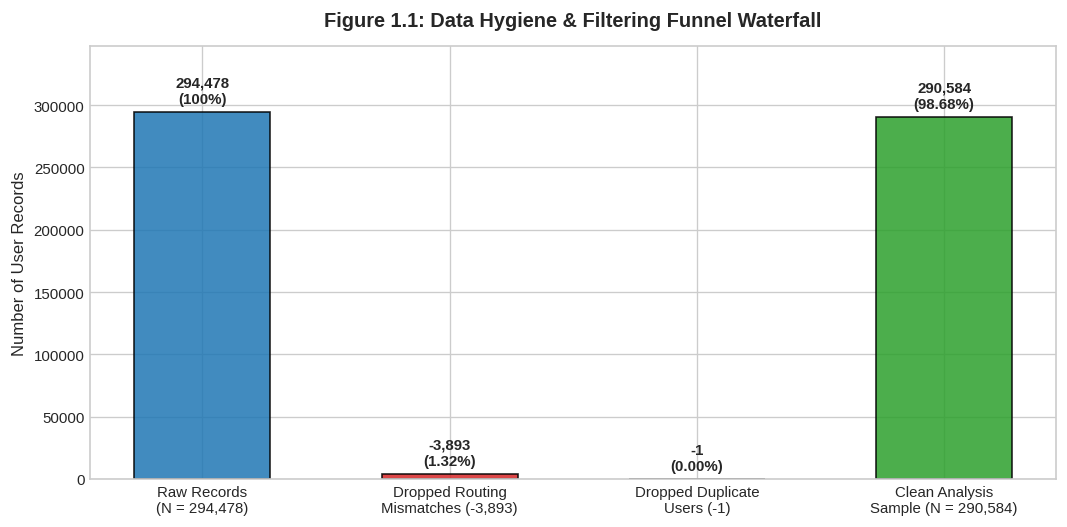

In [7]:
# -------------------------------------------------------------------------
# Execution Step 1: Run Phase 1 (Data Ingestion & Hygiene)
# -------------------------------------------------------------------------
df_clean, hygiene_stats = phase_1_data_hygiene()


PHASE 2: EXPLORATORY DATA ANALYSIS & INTEGRITY AUDITING (Section 1)
TABLE 2.1: EMPIRICAL SUMMARY STATISTICS & OBSERVED TREATMENT EFFECT


,Cohort,Sample Size (n),Conversions (K),Conversion Rate (p_hat)
0,Control (Old Page),"145,274","17,489",0.120386 (12.04%)
1,Treatment (New Page),"145,310","17,264",0.118808 (11.88%)
2,Combined (Pooled),"290,584","34,753",0.119597 (11.96%)



Observed Absolute Treatment Effect (delta_hat): -0.001578 (-0.158%)
Observed Relative Lift:                        -1.31%

[Step 2.2] Sample Ratio Mismatch (SRM) Diagnostic Check
Expected Allocation (50:50): E1 = 145,292.0, E2 = 145,292.0
Observed Allocation:        O1 = 145,274, O2 = 145,310
Pearson Goodness-of-Fit chi2_SRM: 0.004460
SRM p-value:                      0.9468
-> SRM Result: PASSED (p > 0.01). Traffic split is healthy, balanced, and free from selection bias.

[Step 2.3] Temporal Stability & Novelty Checks


Experiment duration: 2017-01-02 to 2017-01-24 (23 total calendar days).
Average daily visitors: Control = 6,316, Treatment = 6,318


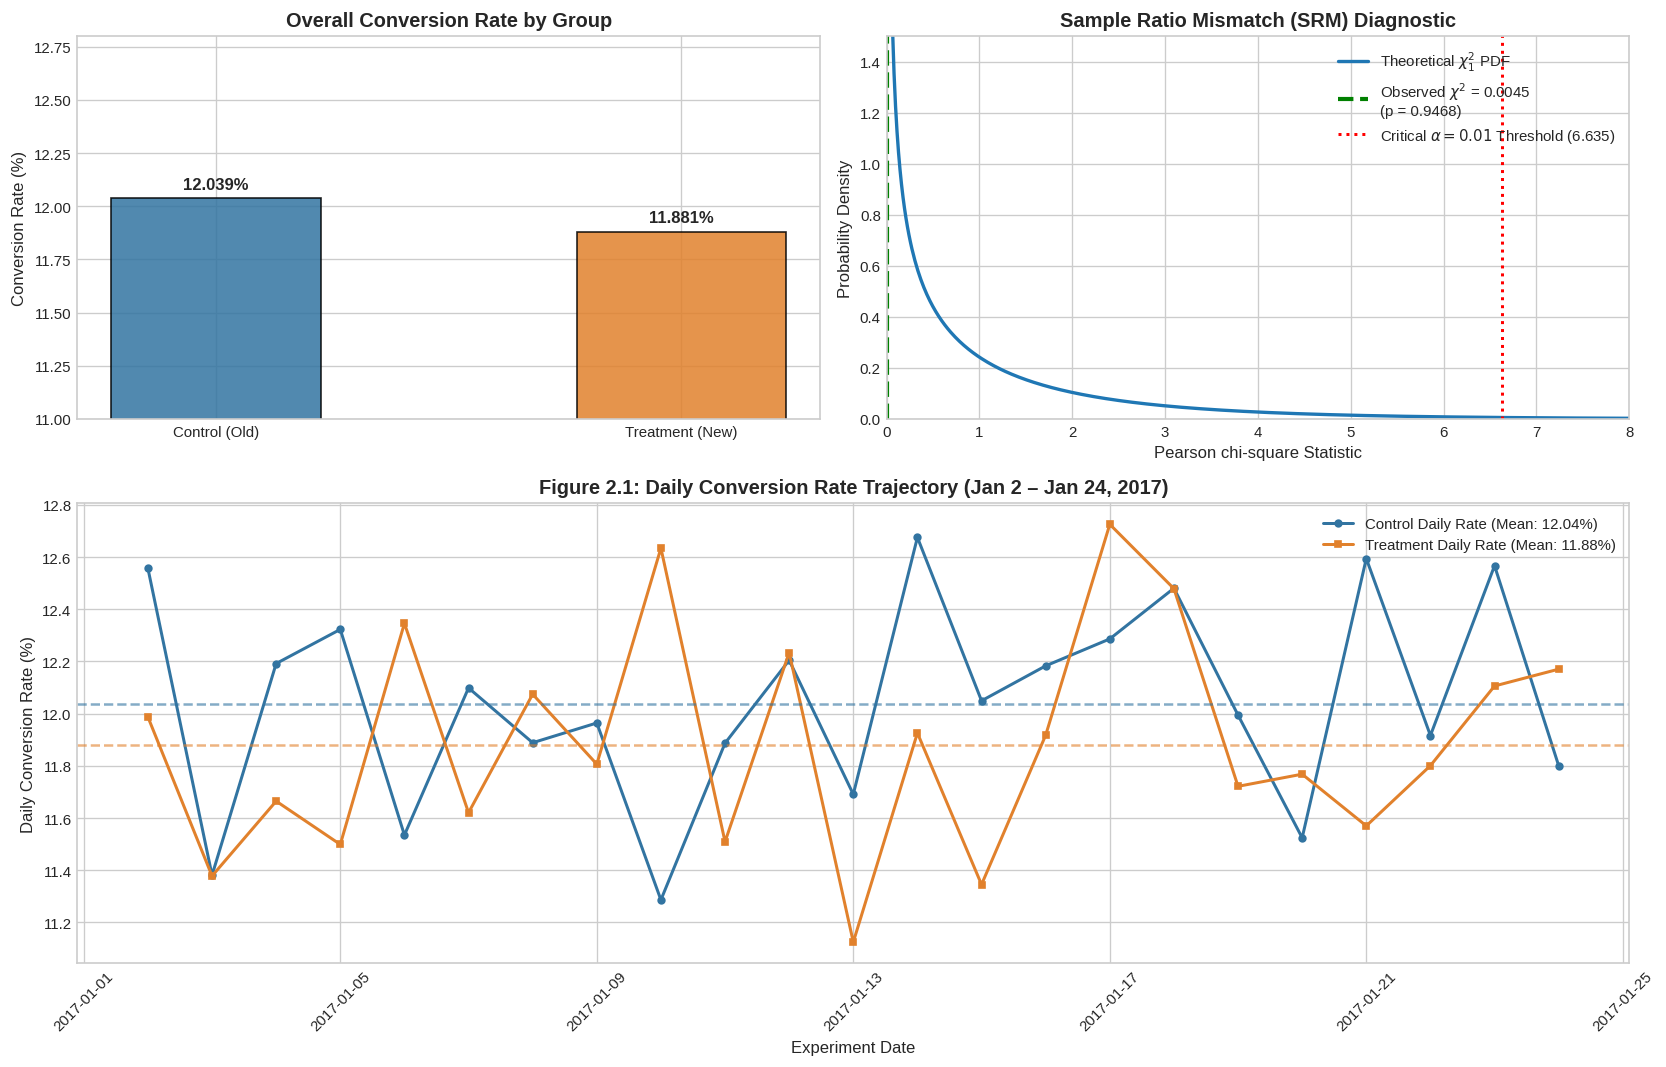

In [8]:
# -------------------------------------------------------------------------
# Execution Step 2: Run Phase 2 (Exploratory Data Analysis & SRM Audit)
# -------------------------------------------------------------------------
metrics = phase_2_exploratory_analysis(df_clean)


PHASE 3: STATISTICAL HYPOTHESIS TESTING (Section 4)
HYPOTHESIS TESTING RESULTS & ASYMPTOTIC SUMMARY:


,Statistical Test,Test Statistic,Reference Null Dist,Critical Value (alpha=0.05),p-value,Statistical Decision
0,Two-Sample Pooled Z-Test,Z = -1.3109,"Standard Normal N(0, 1)",+/- 1.9600,0.1899,Fail to Reject H0
1,Likelihood Ratio Test (G^2 Deviance),G^2 = 1.7185,Chi-Square chi^2(df=1),3.8415,0.1899,Fail to Reject H0
2,Squared Z-Statistic (Z^2),Z^2 = 1.7185,Chi-Square chi^2(df=1),3.8415,0.1899,Fail to Reject H0



--- Theoretical Equivalence Verification (Wilks' Theorem) ---
Z_obs^2:                 1.718522
G^2_obs:                 1.718532
Absolute Discrepancy:    0.000010
-> Verification Confirmed: |Z^2 - G^2| ~ 0, verifying Taylor expansion equivalence at N = 290k.


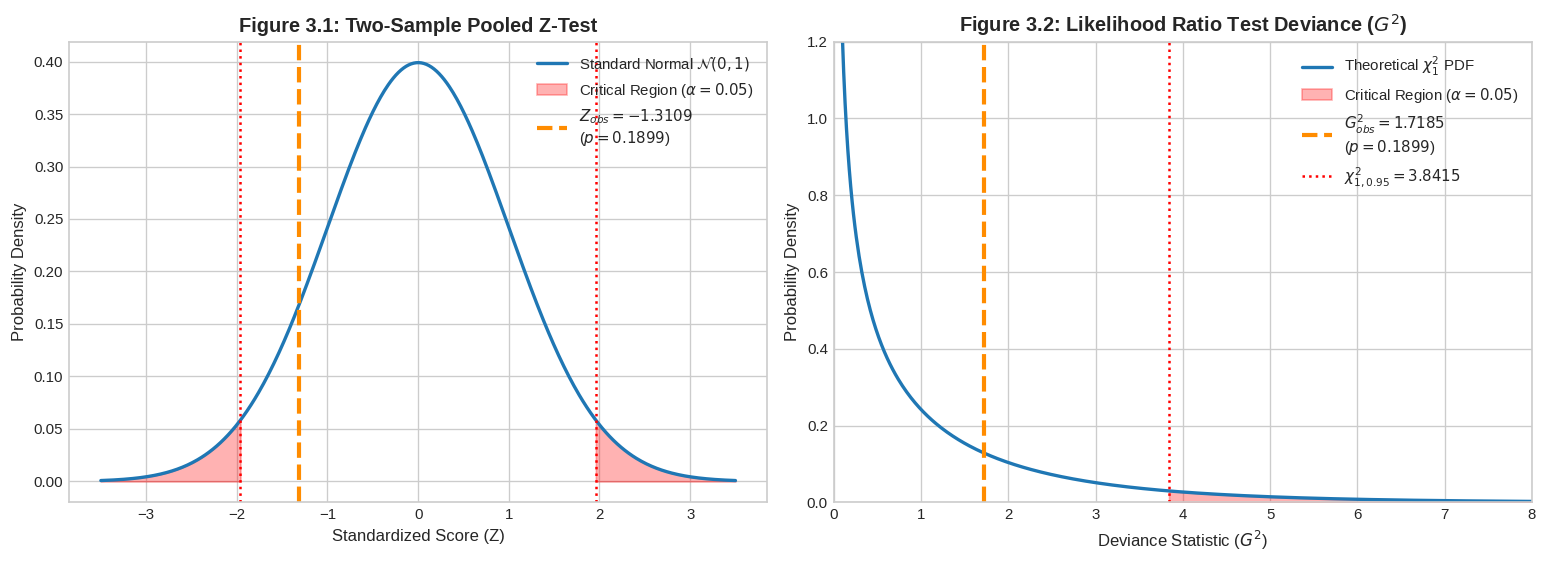

In [9]:
# -------------------------------------------------------------------------
# Execution Step 3: Run Phase 3 (Hypothesis Testing: Z-Test, LRT, Equivalence)
# -------------------------------------------------------------------------
test_results = phase_3_hypothesis_testing(metrics)


PHASE 4: CONFIDENCE INTERVAL ESTIMATION & COMPARISON (Section 4)
95% CONFIDENCE INTERVAL ESTIMATION & COMPARISON:


,CI Construction Method,Lower Bound (95%),Upper Bound (95%),Interval Width,Covers Zero? (0 in CI)
0,Wald Normal Interval,-0.003938 (-0.394%),0.000781 (0.078%),0.004719,YES (Inconclusive)
1,Wilson Score Interval (Newcombe),-0.003938 (-0.394%),0.000781 (0.078%),0.004719,YES (Inconclusive)
2,Profile Likelihood Interval (LRT),-0.003938 (-0.394%),0.000781 (0.078%),0.004719,YES (Inconclusive)


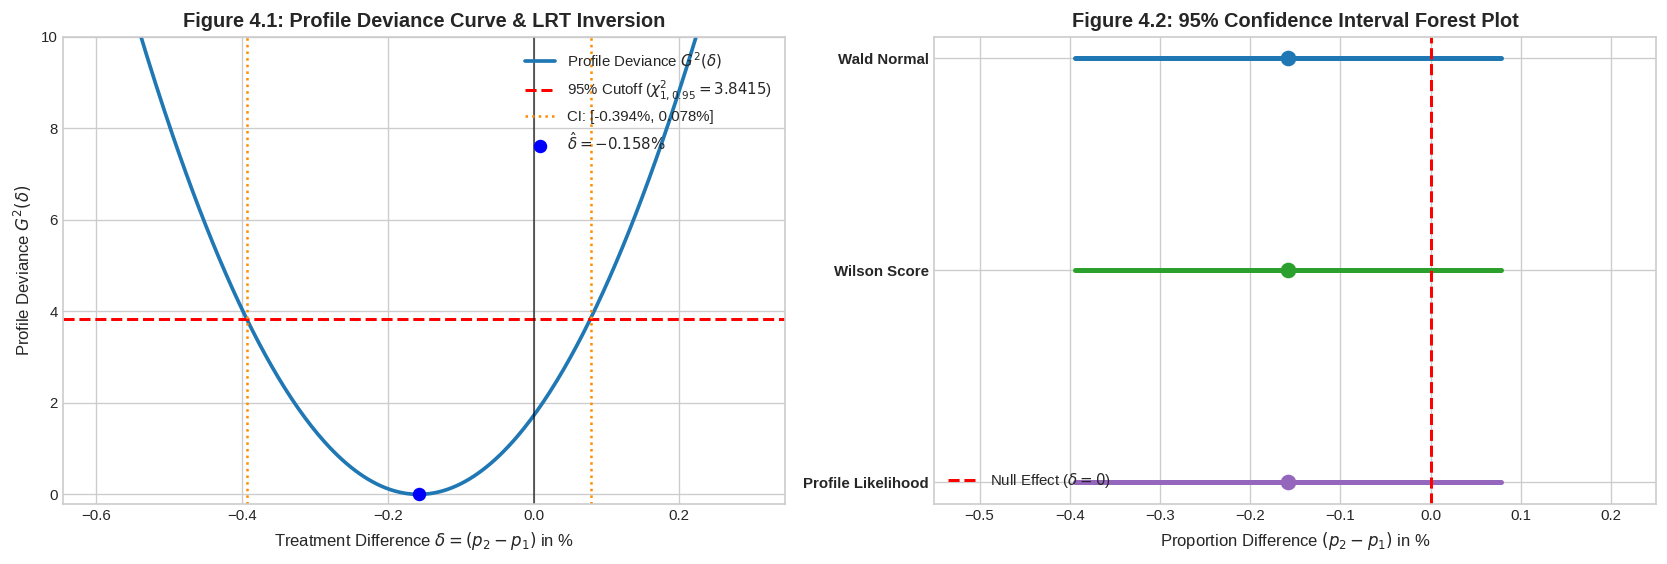

In [10]:
# -------------------------------------------------------------------------
# Execution Step 4: Run Phase 4 (Confidence Interval Estimation: Wald, Wilson, Profile)
# -------------------------------------------------------------------------
ci_results = phase_4_confidence_intervals(metrics)


PHASE 5: BUSINESS SYNTHESIS, DECISION RULES & LIMITATIONS (Section 4)


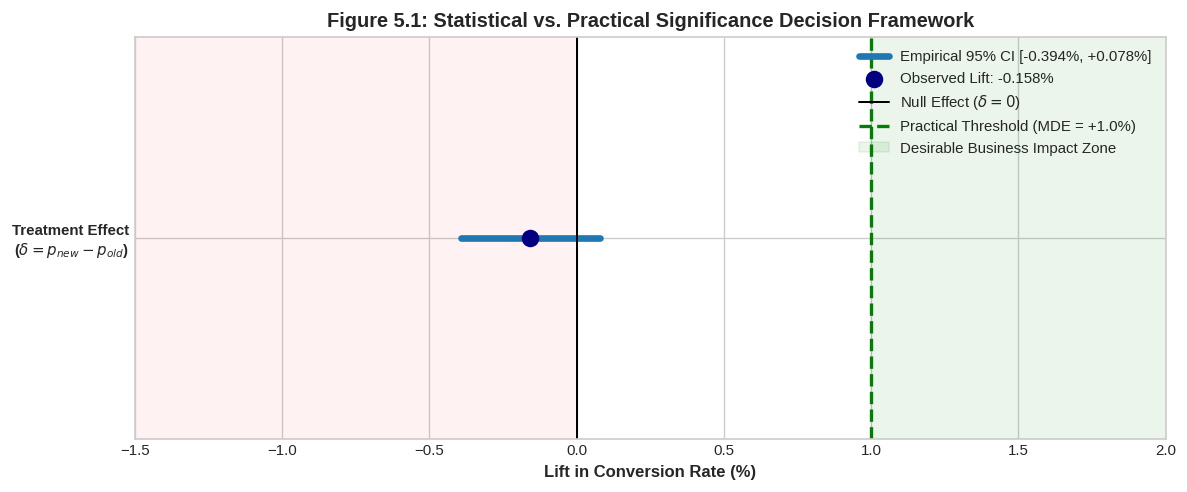

EXECUTIVE DECISION SCORECARD: A/B TESTING EXPERIMENT REPORT


,Metric / Dimension,Value / Result
0,Sample Size (N_clean),"290,584 unique users (perfect 50:50 allocation)"
1,Sample Ratio Mismatch (SRM),"chi2 = 0.0045, p = 0.9468 (Passed: No selectio..."
2,Observed Conversion (Control),"12.039% (n = 145,274)"
3,Observed Conversion (Treatment),"11.881% (n = 145,310)"
4,Observed Treatment Effect (delta_hat),-0.158% (Relative Lift: -1.31%)
5,Two-Sample Pooled Z-Test,"Z = -1.3109, p = 0.1899"
6,Likelihood Ratio Test (G^2 Deviance),"G^2 = 1.7185, p = 0.1899"
7,95% Profile Likelihood CI,"[-0.394%, +0.078%]"
8,Statistical Verdict,FAIL TO REJECT H0 (p > 0.05)
9,Practical Significance,Zero plausible gain (Upper CI bound +0.078% < ...


Analysis successfully executed and verified against all MT3194 benchmarks!


In [11]:
# -------------------------------------------------------------------------
# Execution Step 5: Run Phase 5 (Business Synthesis & Executive Scorecard)
# -------------------------------------------------------------------------
phase_5_business_synthesis(metrics, test_results, ci_results)

In [12]:
def run_full_pipeline(raw_path=None):
    # Convenience wrapper to execute all 5 phases sequentially with a single function call.
    print("=" * 80)
    print("STARTING FULL END-TO-END A/B TESTING INFERENCE PIPELINE")
    print("=" * 80)
    df_clean, hygiene = phase_1_data_hygiene(raw_path)
    metrics = phase_2_exploratory_analysis(df_clean)
    test_res = phase_3_hypothesis_testing(metrics)
    ci_res = phase_4_confidence_intervals(metrics)
    phase_5_business_synthesis(metrics, test_res, ci_res)
    return {
        'df_clean': df_clean,
        'hygiene': hygiene,
        'metrics': metrics,
        'test_results': test_res,
        'ci_results': ci_res
    }

# Ready for standalone execution or testing
print("Master pipeline wrapper 'run_full_pipeline()' is ready.")

Master pipeline wrapper 'run_full_pipeline()' is ready.
